# Kinyarwanda News Topic Classification

Classifying Kinyarwanda news articles into 14 topics using the KINNEWS dataset (Niyongabo et al., 2020).

- GitHub: https://github.com/amaliza-shal/Text-Classification-Summative
- Live demo: _Hugging Face Space link_
- Demo video: _video link_

Training the BiLSTMs and Transformers takes a long time on CPU, so the notebook loads saved checkpoints when they exist. Set `RETRAIN = True` to train them again.

## 1. Problem

We want to predict the topic of a Kinyarwanda news article (politics, sport, health, …). Kinyarwanda has very little labelled NLP data, and a classifier like this could help newsrooms and archives tag articles automatically.

The task is hard because Kinyarwanda is agglutinative (one stem, many word forms), its spelling varies, and the dataset is small and unbalanced.

Other KINNEWS classifiers already exist on Hugging Face, but they report one score. We focus on *why* models fail: duplicates, unseen news websites and inconsistent labels.

**What we used vs. what we built**

| Used as is | Built by us |
|---|---|
| KINNEWS dataset (MIT) | Data audit, cleaning, deduplication, splits |
| AfroXLMR-mini (MIT) and mMiniLMv2 pretrained weights | All 8 experiments and their training code |
| scikit-learn, gensim, PyTorch, Transformers, Gradio | Evaluation, error analysis, leakage check, web app |

## 2. Setup

In [1]:
import json, platform
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch, sklearn, transformers, gensim
from IPython.display import display, Markdown, Image

from src.config import DATA_RAW, DATA_PROCESSED, MODELS_DIR, RESULTS_DIR, FIGURES_DIR, LABELS, SEED
from src.evaluate import evaluate

RETRAIN = False
pd.set_option("display.max_colwidth", 120)
plt.rcParams["figure.dpi"] = 110
np.random.seed(SEED)
torch.manual_seed(SEED)

print("python", platform.python_version(), "| torch", torch.__version__, "| transformers", transformers.__version__,
      "| scikit-learn", sklearn.__version__, "| gensim", gensim.__version__)

C:\Users\EVOTECH SOL\Desktop\Text Classification Summative\Text-Classification-Summative\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


python 3.11.9 | torch 2.14.1+cpu | transformers 5.19.0 | scikit-learn 1.9.1 | gensim 4.4.0


## 3. Data

KINNEWS is real news from 15 Rwandan websites and 5 newspapers. The authors grouped the publishers' 48 categories into 14 topics, and two native speakers labelled each article. We use the raw version (original text and URLs) with the official train/test split.

In [2]:
import src.download

raw = {s: pd.read_parquet(DATA_RAW / f"kinnews_{s}.parquet") for s in ("train", "test")}
for s, df in raw.items():
    print(s, df.shape)
raw["train"].head(3)

C:\Users\EVOTECH SOL\Desktop\Text Classification Summative\Text-Classification-Summative\data\raw\kinnews_train.parquet 11308532 bytes
C:\Users\EVOTECH SOL\Desktop\Text Classification Summative\Text-Classification-Summative\data\raw\kinnews_test.parquet 5379399 bytes


train (17014, 6)
test (4254, 6)


,label,kin_label,en_label,url,title,content
0,5,amateka,history,https://www.kigalitoday.com/amakuru/mu-mateka/article/yihakanye-uwo-yabyaye-animisha-na-nyina-ibyo-yagombaga-guhabwa...,Yihakanye uwo yabyaye animisha na nyina ibyo yagombaga guhabwa nk’abandi batishoboye,"Icyatumye amwihakana ngo ni uko yanze kujya akomeza kuryamana nawe, nk’uko nyirubwite abivuga. Ati: ”Umugabo wanjye..."
1,5,amateka,history,https://www.kigalitoday.com/amakuru/mu-mateka/Barasaba-ko-ba-kavukire-boroherezwa-ntibakomeze-kwimurwa-mu-mijyi,Barasaba ko ba kavukire boroherezwa ntibakomeze kwimurwa mu mijyi,"Iyi nama yateraniye mu cyumba cy’inama cya Bonni Concilli tariki 14/06/2012, yari igamije kungurana ibitekerezo ku ..."
2,5,amateka,history,https://www.kigalitoday.com/amakuru/mu-mateka/Abantu-9-bashakishwa-cyane-na-ICTR-na-USA-bashinjwa-kugira-uruhare-muri,Abantu 9 bashakishwa cyane na ICTR na USA bashinjwa kugira uruhare muri Jenoside yakorewe abatutsi,Leta zunze Ubumwe z’Amerika kandi zanijeje uzatanga amakuru ko izina rye rizagirwa ibanga ndetse akazacungirwa umut...


In [3]:
raw["train"].groupby("label")[["kin_label", "en_label"]].first().assign(name=LABELS)

,kin_label,en_label,name
label,,,
0,politiki,politic,politics
1,imikino,sport,sport
2,ubukungu,economy,economy
3,ubuzima,health,health
4,imyidagaduro,entertainment,entertainment
5,amateka,history,history
6,ikoranabuhanga,technology,technology
7,ubukerarugendo,tourism,tourism
8,umuco,culture,culture


## 4. Data quality check
We check for duplicates, label conflicts, broken encoding and where the articles come from before training anything.

In [4]:
for s, df in raw.items():
    dup = df.duplicated(["title", "content"]).sum()
    multi = df.groupby("content")["label"].nunique()
    print(f"{s}: {len(df)} rows, {dup} duplicates ({dup / len(df):.0%}), {(multi > 1).sum()} articles with 2+ labels")

print("most repeated training article appears", raw["train"]["content"].value_counts().iloc[0], "times")

train: 17014 rows, 9379 duplicates (55%), 157 articles with 2+ labels
test: 4254 rows, 750 duplicates (18%), 1 articles with 2+ labels
most repeated training article appears 80 times


More than half of the training rows are duplicates, and some articles carry two different labels. Both have to go, or the model trains on repeats and validation leaks.

In [5]:
text = raw["train"]["title"] + " " + raw["train"]["content"]
bad = text.str.contains("â\x80")
example = text[bad].iloc[0]
i = example.find("â\x80")
print("articles with broken encoding:", bad.sum())
print(repr(example[max(0, i - 40): i + 40]))

articles with broken encoding: 71
'23 Mata 2019 ubwo hatangizwaga gahunda yâ\x80\x99ubwishingizi mu buhinzi nâ\x80\x99ubworozi,'


Some text was decoded with the wrong encoding (`’` became `â\x80\x99`). `fix_mojibake` repairs it.

In [6]:
def source(urls):
    return urls.str.extract(r"https?://(?:www\.)?([^/]+)")[0]

src_train, src_test = source(raw["train"]["url"]), source(raw["test"]["url"])
print("websites in train:", src_train.nunique(), "| websites in test:", src_test.nunique())
print("test websites never seen in train:", sorted(set(src_test) - set(src_train)))
src_test.value_counts(normalize=True).round(3)

websites in train: 18 | websites in test: 3
test websites never seen in train: ['igihe.com', 'kigalipost.com']


0
igihe.com         0.451
muhabura.rw       0.391
kigalipost.com    0.158
Name: proportion, dtype: float64

About half of the test set comes from two websites that never appear in training. So the test set mostly measures how well a model works on a new news site. We keep the official split anyway because it is the standard benchmark.

## 5. Preprocessing and splits

- Input = `title . body`, because the title is a strong topic signal.
- `text` (TF-IDF, Word2Vec, BiLSTM): fix encoding, lowercase, drop URLs/numbers/punctuation. Apostrophes become spaces so `n'abana` gives `abana`.
- `text_tf` (Transformers): only fix encoding, since their tokenizer was trained on normal cased text.
- Drop duplicates, conflicting labels and test articles that also appear in train, then take 10% of train (stratified) for validation.

In [7]:
from src.preprocess import clean_text, light_clean
from src import preprocess

sample = "Minisiteri y’Ibikorwa remezo (MININFRA) yemereye ibigo 20 by’ubwubatsi gusubukura imirimo."
print("original:", sample)
print("text_tf :", light_clean(sample))
print("text    :", clean_text(sample))

original: Minisiteri y’Ibikorwa remezo (MININFRA) yemereye ibigo 20 by’ubwubatsi gusubukura imirimo.
text_tf : Minisiteri y’Ibikorwa remezo (MININFRA) yemereye ibigo 20 by’ubwubatsi gusubukura imirimo.
text    : minisiteri y ibikorwa remezo mininfra yemereye ibigo by ubwubatsi gusubukura imirimo


In [8]:
preprocess.main()
splits = {s: pd.read_csv(DATA_PROCESSED / f"{s}.csv") for s in ("train", "val", "test")}
train, val, test = splits["train"], splits["val"], splits["test"]

{
  "train_raw": {
    "rows": 17014,
    "too_short": 0,
    "conflicting_label_rows": 1453,
    "duplicate_rows": 8098,
    "unique": 7463
  },
  "test_raw": {
    "rows": 4254,
    "too_short": 4,
    "conflicting_label_rows": 0,
    "duplicate_rows": 791,
    "unique": 3459,
    "also_in_train": 3
  },
  "sizes": {
    "train": 6716,
    "val": 747,
    "test": 3456
  },
  "class_counts": {
    "train": {
      "politics": 1590,
      "sport": 877,
      "economy": 998,
      "health": 975,
      "entertainment": 895,
      "history": 199,
      "technology": 135,
      "tourism": 30,
      "culture": 69,
      "fashion": 34,
      "religion": 401,
      "environment": 34,
      "education": 104,
      "relationship": 375
    },
    "val": {
      "politics": 177,
      "sport": 97,
      "economy": 111,
      "health": 108,
      "entertainment": 100,
      "history": 22,
      "technology": 15,
      "tourism": 3,
      "culture": 8,
      "fashion": 4,
      "religion": 44,
    

## 6. Exploring the data

label,politics,sport,economy,health,entertainment,history,technology,tourism,culture,fashion,religion,environment,education,relationship
train,1590,877,998,975,895,199,135,30,69,34,401,34,104,375
val,177,97,111,108,100,22,15,3,8,4,44,4,12,42
test,315,744,174,272,774,8,103,76,136,90,255,100,70,339


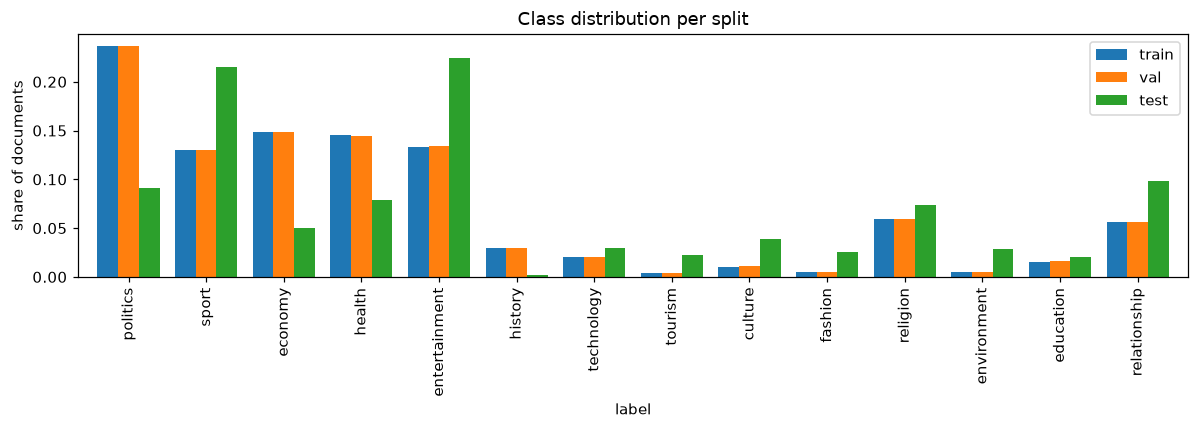

In [9]:
counts = pd.DataFrame({s: df["label"].value_counts() for s, df in splits.items()}).reindex(LABELS)
display(counts.T)
(counts / counts.sum()).plot.bar(figsize=(11, 4), width=0.8)
plt.ylabel("share of documents"); plt.title("Class distribution per split")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "class_distribution.png", dpi=150); plt.show()

Classes are very unbalanced (politics 1,590 vs tourism 30) and the test mix is different from train. That's why we use **macro-F1** as the main metric: every topic counts equally.

count     6716.0
mean       362.0
std        300.0
min         20.0
25%        218.0
50%        306.0
75%        428.0
max      11996.0
Name: text, dtype: float64


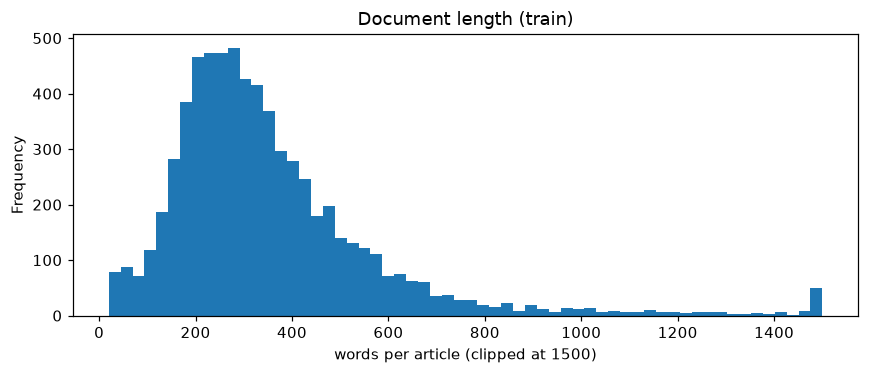

vocabulary: 139,883 words, 55% seen only once
test words not seen in train: 5.1%
most frequent: ['mu', 'n', 'ko', 'ku', 'y', 'muri', 'na', 'wa', 'ya', 'w', 'rwanda', 'ni', 'ngo', 'ari', 'kuri']


In [10]:
n_words = train["text"].str.split().str.len()
print(n_words.describe().round(0))
n_words.clip(upper=1500).plot.hist(bins=60, figsize=(8, 3.5))
plt.xlabel("words per article (clipped at 1500)"); plt.title("Document length (train)")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "length_hist.png", dpi=150); plt.show()

vocab = Counter(w for t in train["text"] for w in t.split())
test_tokens = [w for t in test["text"] for w in t.split()]
print(f"vocabulary: {len(vocab):,} words, {sum(c == 1 for c in vocab.values()) / len(vocab):.0%} seen only once")
print(f"test words not seen in train: {sum(w not in vocab for w in test_tokens) / len(test_tokens):.1%}")
print("most frequent:", [w for w, _ in vocab.most_common(15)])

A huge vocabulary where most words appear once: typical for an agglutinative language. This is why we also try character n-grams and subword models.

## 7. Experiment plan

Each experiment changes one thing so we can see its effect.

| ID | Model | Why |
|---|---|---|
| E0 | Majority class | Lowest possible score |
| E1 | Word TF-IDF + logistic regression | Baseline: simple and strong for topics |
| E2 | E1 + class weights | Help the rare topics |
| E3 | Character TF-IDF + linear SVM | Handle word variations |
| E4 | BiLSTM + attention, random embeddings | Does word order help? |
| E5 | BiLSTM + attention, Word2Vec embeddings | Do pretrained embeddings help with little data? |
| E6 | AfroXLMR-mini fine-tuned | Transformer pretrained on African languages |
| E7 | mMiniLM fine-tuned | Same model without the African training |
| E8 | E6 with a higher learning rate | Was E6 undertrained? |

## 8. Baselines (E0–E3)
TF-IDF turns each article into weighted n-gram counts. Class weights make mistakes on rare topics cost more. Character n-grams let different forms of the same word (*abanyeshuri*, *abanyeshuli*) share features.

In [11]:
import joblib
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.svm import LinearSVC

word_tfidf = dict(ngram_range=(1, 2), min_df=2, max_df=0.9, sublinear_tf=True, max_features=200_000)
baselines = {
    "E0_majority": DummyClassifier(strategy="most_frequent"),
    "E1_tfidf_logreg": make_pipeline(TfidfVectorizer(**word_tfidf), LogisticRegression(C=10, max_iter=2000)),
    "E2_tfidf_logreg_balanced": make_pipeline(
        TfidfVectorizer(**word_tfidf), LogisticRegression(C=10, max_iter=2000, class_weight="balanced")),
    "E3_char_tfidf_svm_balanced": make_pipeline(
        TfidfVectorizer(analyzer="char_wb", ngram_range=(2, 5), min_df=2, sublinear_tf=True, max_features=300_000),
        LinearSVC(C=0.5, class_weight="balanced", random_state=SEED)),
}
for name, model in baselines.items():
    model.fit(train["text"], train["label"])
    evaluate(name, val, model.predict(val["text"]), split="val")
    evaluate(name, test, model.predict(test["text"]), split="test")
    if name != "E0_majority":
        joblib.dump(model, MODELS_DIR / f"{name}.joblib")

{"model": "E0_majority", "split": "val", "accuracy": 0.2369, "macro_precision": 0.0169, "macro_recall": 0.0714, "macro_f1": 0.0274, "weighted_f1": 0.0908}


{"model": "E0_majority", "split": "test", "accuracy": 0.0911, "macro_precision": 0.0065, "macro_recall": 0.0714, "macro_f1": 0.0119, "weighted_f1": 0.0152}


{"model": "E1_tfidf_logreg", "split": "val", "accuracy": 0.7805, "macro_precision": 0.643, "macro_recall": 0.5515, "macro_f1": 0.5789, "weighted_f1": 0.7709}


{"model": "E1_tfidf_logreg", "split": "test", "accuracy": 0.6907, "macro_precision": 0.5669, "macro_recall": 0.4595, "macro_f1": 0.4109, "weighted_f1": 0.657}


{"model": "E2_tfidf_logreg_balanced", "split": "val", "accuracy": 0.7898, "macro_precision": 0.6638, "macro_recall": 0.6506, "macro_f1": 0.6464, "weighted_f1": 0.7843}


{"model": "E2_tfidf_logreg_balanced", "split": "test", "accuracy": 0.719, "macro_precision": 0.6794, "macro_recall": 0.5256, "macro_f1": 0.4872, "weighted_f1": 0.6988}


{"model": "E3_char_tfidf_svm_balanced", "split": "val", "accuracy": 0.7898, "macro_precision": 0.7756, "macro_recall": 0.747, "macro_f1": 0.7365, "weighted_f1": 0.7887}


{"model": "E3_char_tfidf_svm_balanced", "split": "test", "accuracy": 0.761, "macro_precision": 0.6544, "macro_recall": 0.6104, "macro_f1": 0.5767, "weighted_f1": 0.7534}


- Class weights: macro-F1 0.41 → 0.49 (without them, fashion and environment are never predicted).
- Character n-grams: macro-F1 0.58, accuracy 0.76, the best so far.

## 9. Word2Vec
We train skip-gram embeddings on the training text only. They are used to initialise the BiLSTM in E5.

In [12]:
from gensim.models import KeyedVectors, Word2Vec

kv_path = MODELS_DIR / "w2v_kin_100d.kv"
if RETRAIN or not kv_path.exists():
    w2v = Word2Vec([t.split() for t in train["text"]], vector_size=100, window=5, min_count=2, sg=1,
                   negative=10, epochs=10, workers=4, seed=SEED)
    w2v.wv.save(str(kv_path))
kv = KeyedVectors.load(str(kv_path))
print("vocabulary:", len(kv))
for w in ["umupira", "ubukungu", "indirimbo", "kiliziya", "abanyeshuri", "urukundo"]:
    print(f"{w:12s} ->", [n for n, _ in kv.most_similar(w, topn=6)])

vocabulary: 63183
umupira      -> ['amaguru', 'mupira', 'bikinirwaho', 'batakiwukina', 'amagru', 'ishirahamwe']
ubukungu     -> ['bukungu', 'bwifashe', 'bujegajega', 'kristalina', 'buzazamuka', 'iterambere']
indirimbo    -> ['ndirimbo', 'album', 'albums', 'uririmba', 'injyana', 'zihimbaza']
kiliziya     -> ['gatolika', 'gaturika', 'gatulika', 'diyosezi', 'paruwasi', 'diyoseze']
abanyeshuri  -> ['biga', 'abarimu', 'abiga', 'abanyeshuli', 'mashuri', 'abarezi']
urukundo     -> ['rwanyu', 'nyarwo', 'rukundo', 'mukundana', 'abashakanye', 'rurambye']


The neighbours make sense: *kiliziya* (church) → *gatolika/gaturika/gatulika* (three spellings of "Catholic"), *abanyeshuri* (students) → *abarimu* (teachers).

## 10. BiLSTM with attention (E4, E5)

Word ids (first 400 words) → 100-d embeddings → BiLSTM (128 per direction) → attention pooling → 14 classes.

- Bidirectional, so each word sees context on both sides.
- Attention picks out the words that matter for the topic.
- Adam lr 2e-3, batch 32, 12 epochs, class-weighted loss, keep the epoch with the best validation macro-F1.

In [13]:
from src.bilstm import BiLSTMAttention, train as train_bilstm

net = BiLSTMAttention(vocab_size=63_185)
print(net)
print(f"parameters: {sum(p.numel() for p in net.parameters()):,}")

BiLSTMAttention(
  (emb): Embedding(63185, 100, padding_idx=0)
  (lstm): LSTM(100, 128, batch_first=True, bidirectional=True)
  (att): Linear(in_features=256, out_features=1, bias=True)
  (drop): Dropout(p=0.4, inplace=False)
  (out): Linear(in_features=256, out_features=14, bias=True)
)
parameters: 6,557,875


{"model": "E4_bilstm_random", "split": "val", "accuracy": 0.7028, "macro_precision": 0.6031, "macro_recall": 0.6525, "macro_f1": 0.6162, "weighted_f1": 0.7048}


{"model": "E4_bilstm_random", "split": "test", "accuracy": 0.6291, "macro_precision": 0.5605, "macro_recall": 0.4884, "macro_f1": 0.4674, "weighted_f1": 0.648}


{"model": "E5_bilstm_w2v", "split": "val", "accuracy": 0.7363, "macro_precision": 0.6328, "macro_recall": 0.7291, "macro_f1": 0.6651, "weighted_f1": 0.7401}


{"model": "E5_bilstm_w2v", "split": "test", "accuracy": 0.6739, "macro_precision": 0.5911, "macro_recall": 0.5925, "macro_f1": 0.5449, "weighted_f1": 0.69}


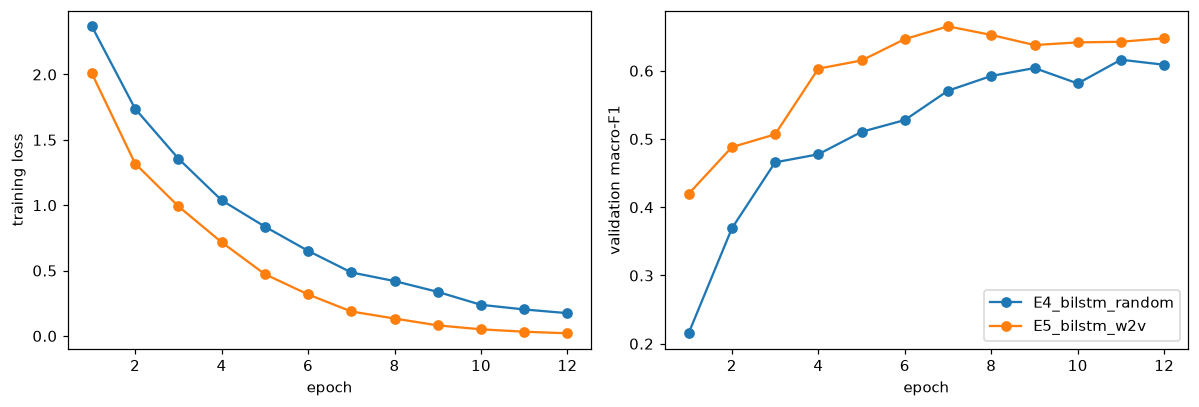

In [14]:
from src.bilstm import encode, predict

for emb, name in (("random", "E4_bilstm_random"), ("w2v", "E5_bilstm_w2v")):
    if RETRAIN or not (MODELS_DIR / f"{name}.pt").exists():
        train_bilstm(emb=emb)
    # evaluate the saved best checkpoint
    vocab_ids = json.loads((MODELS_DIR / f"{name}_vocab.json").read_text())
    model = BiLSTMAttention(len(vocab_ids) + 2)
    model.load_state_dict(torch.load(MODELS_DIR / f"{name}.pt"))
    for split, df in (("val", val), ("test", test)):
        evaluate(name, df, [LABELS[i] for i in predict(model, encode(df["text"], vocab_ids))], split=split)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name in ("E4_bilstm_random", "E5_bilstm_w2v"):
    h = pd.read_csv(RESULTS_DIR / f"{name}_history.csv")
    ax[0].plot(h["epoch"], h["train_loss"], marker="o", label=name)
    ax[1].plot(h["epoch"], h["val_macro_f1"], marker="o", label=name)
ax[0].set(xlabel="epoch", ylabel="training loss"); ax[1].set(xlabel="epoch", ylabel="validation macro-F1")
ax[1].legend(); plt.tight_layout(); plt.savefig(FIGURES_DIR / "bilstm_curves.png", dpi=150); plt.show()

Word2Vec helps: best validation F1 0.665 (epoch 7) vs 0.616 (epoch 11) with random embeddings. Both overfit after about 7 epochs, which is why we keep the best epoch.

## 11. Fine-tuned Transformers (E6–E8)

AfroXLMR-mini is mMiniLMv2 with extra training on 17 African languages, including Kinyarwanda (Alabi et al., 2022). E7 uses the original mMiniLMv2 with the same settings, so the difference shows what the African training adds.

Settings: 128 subword tokens, batch 16, 4 epochs, lr 5e-5 (E8: 1.5e-4), class-weighted loss, best epoch on validation.

We froze the word-embedding layer (96M of 118M parameters) and used 128 tokens so training fits on an 8 GB laptop CPU. The trade-off is that the model only reads about the first 50 words of each article.

In [15]:
from transformers import AutoTokenizer

tok = AutoTokenizer.from_pretrained("Davlan/afro-xlmr-mini")
print(tok.tokenize("Abanyeshuri b’amashuri yisumbuye batangiye ibizamini bya Leta"))
lengths = np.array([len(tok(t)["input_ids"]) for t in train["text_tf"].sample(500, random_state=SEED)])
print(f"median subword tokens per article: {np.median(lengths):.0f}; fit in 128 tokens: {np.mean(lengths <= 128):.0%}")

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (557 > 512). Running this sequence through the model will result in indexing errors


['▁Aba', 'ny', 'es', 'huri', '▁b', '’', 'amas', 'huri', '▁y', 'is', 'umbu', 'ye', '▁batang', 'iye', '▁i', 'biz', 'amini', '▁by', 'a', '▁Leta']


median subword tokens per article: 708; fit in 128 tokens: 2%


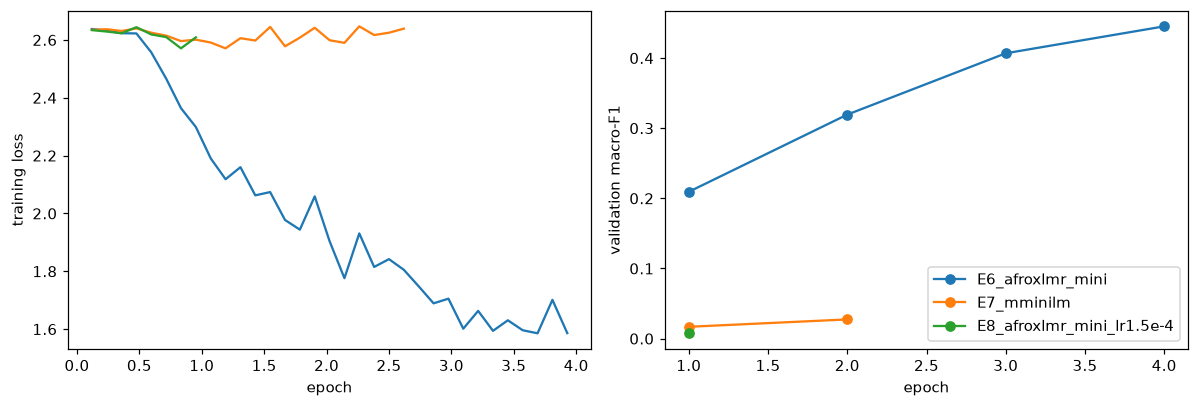

In [16]:
from src.finetune import train as finetune

runs = {"E6_afroxlmr_mini": ("Davlan/afro-xlmr-mini", 5e-5),
        "E7_mminilm": ("nreimers/mMiniLMv2-L12-H384-distilled-from-XLMR-Large", 5e-5),
        "E8_afroxlmr_mini_lr1.5e-4": ("Davlan/afro-xlmr-mini", 1.5e-4)}
for name, (checkpoint, lr) in runs.items():
    # E7 was stopped after 2.6 epochs, so only its history exists
    if RETRAIN or not (RESULTS_DIR / f"{name}_history.csv").exists():
        finetune(model_name=checkpoint, name=name, lr=lr)

fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
for name in runs:
    h = pd.read_csv(RESULTS_DIR / f"{name}_history.csv")
    tr, ev = h.dropna(subset=["loss"]), h.dropna(subset=["eval_macro_f1"])
    ax[0].plot(tr["epoch"], tr["loss"], label=name)
    ax[1].plot(ev["epoch"], ev["eval_macro_f1"], marker="o", label=name)
ax[0].set(xlabel="epoch", ylabel="training loss"); ax[1].set(xlabel="epoch", ylabel="validation macro-F1")
ax[1].legend(); plt.tight_layout(); plt.savefig(FIGURES_DIR / "transformer_curves.png", dpi=150); plt.show()

- **E6** learns slowly but steadily (val macro-F1 0.21 → 0.45) and was still improving at the end.
- **E7** (no African-language training) didn't learn at all at the same learning rate: loss stuck at chance (2.65 ≈ ln 14). Stopped after 2.6 epochs.
- **E8** (3× learning rate) collapsed to one class in the first epoch (val macro-F1 0.008). Stopped.
- So the African pretraining makes fine-tuning easier, but these small Transformers are very sensitive to the learning rate and undertrained under our CPU limits.

## 12. Results

Metrics: accuracy, precision, recall and F1 per class. Macro averages treat every topic equally, which is why macro-F1 is our main score.

,accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,val_macro_f1
model,,,,,,
E0_majority,0.091,0.006,0.071,0.012,0.015,0.027
E1_tfidf_logreg,0.691,0.567,0.460,0.411,0.657,0.579
E2_tfidf_logreg_balanced,0.719,0.679,0.526,0.487,0.699,0.646
E3_char_tfidf_svm_balanced,0.761,0.654,0.610,0.577,0.753,0.736
E4_bilstm_random,0.629,0.560,0.488,0.467,0.648,0.616
E5_bilstm_w2v,0.674,0.591,0.592,0.545,0.690,0.665
E6_afroxlmr_mini,0.670,0.405,0.449,0.390,0.634,0.445


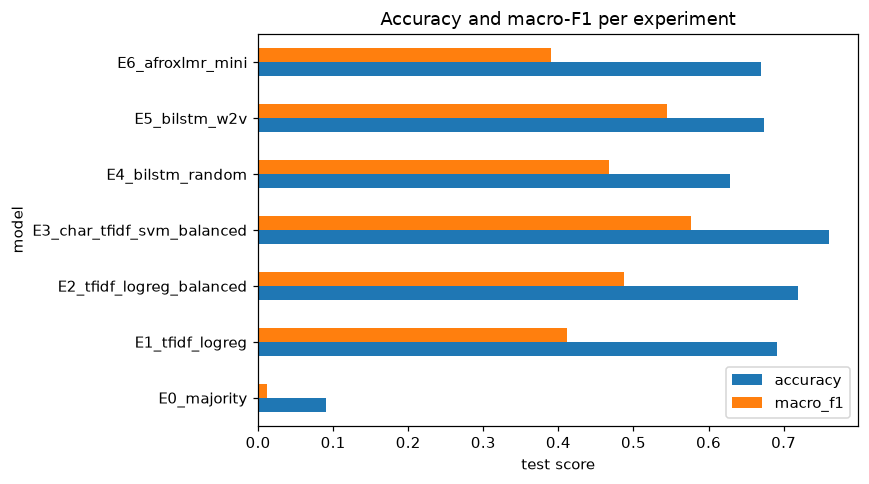

In [17]:
exp = pd.read_csv(RESULTS_DIR / "experiments.csv")
full = exp[exp["split"] == "test"].set_index("model").drop(columns="split").round(3).sort_index()
full["val_macro_f1"] = exp[exp["split"] == "val"].set_index("model")["macro_f1"].round(3)
display(full)

ax = full[["accuracy", "macro_f1"]].plot.barh(figsize=(8, 4.5))
ax.set_xlabel("test score"); ax.set_title("Accuracy and macro-F1 per experiment")
plt.tight_layout(); plt.savefig(FIGURES_DIR / "results_bar.png", dpi=150); plt.show()

- Best model: **E3, character n-grams + SVM** (accuracy 0.761, macro-F1 0.577).
- The biggest gains come from class weights (+0.08) and character n-grams (+0.09).
- Word2Vec helps the BiLSTM (+0.08), but it still stays below E3.
- E6 has similar accuracy to the BiLSTM but much lower macro-F1 (0.390) because it misses the small topics.
- With little data and little compute, the simple model that reads the whole article wins.

### 12.1 Why our scores are lower than the KINNEWS paper
The paper reports about 88.5% accuracy. We test a similar model on a random split of the raw train data, on the same kind of split after removing duplicates, and on the official test set.

In [18]:
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from src.preprocess import load, dedup

def unigram_svm(train_df, test_df):
    vec = TfidfVectorizer(min_df=2, sublinear_tf=True)
    clf = LinearSVC(C=0.5).fit(vec.fit_transform(train_df["text"]), train_df["label"])
    pred = clf.predict(vec.transform(test_df["text"]))
    return accuracy_score(test_df["label"], pred), f1_score(test_df["label"], pred, average="macro")

raw_train, raw_test = load("train"), load("test")
rows = []
for name, df in (("raw train", raw_train), ("deduplicated train", dedup(raw_train)[0])):
    a, b = train_test_split(df, test_size=0.1, stratify=df["label"], random_state=SEED)
    rows.append([f"random 9:1 split of {name}", *unigram_svm(a, b), f"{b['text'].isin(set(a['text'])).mean():.0%}"])
rows.append(["official test set", *unigram_svm(raw_train, raw_test), f"{raw_test['text'].isin(set(raw_train['text'])).mean():.0%}"])
pd.DataFrame(rows, columns=["evaluation", "accuracy", "macro-F1", "held-out docs also in train"]).round(3)

,evaluation,accuracy,macro-F1,held-out docs also in train
0,random 9:1 split of raw train,0.892,0.757,57%
1,random 9:1 split of deduplicated train,0.778,0.601,0%
2,official test set,0.699,0.487,0%


We only get ~89% when the held-out set shares duplicates with training. Without that leakage the same model scores much lower, so our numbers are not directly comparable to the paper's.

### 12.2 Best model per class

best model: E3_char_tfidf_svm_balanced


,train docs,precision,recall,f1-score,support
politics,1590,0.652,0.689,0.670,315.0
economy,998,0.525,0.724,0.609,174.0
health,975,0.646,0.684,0.664,272.0
entertainment,895,0.857,0.850,0.853,774.0
sport,877,0.952,0.960,0.956,744.0
religion,401,0.848,0.788,0.817,255.0
relationship,375,0.733,0.917,0.815,339.0
history,199,0.063,0.750,0.117,8.0
technology,135,0.594,0.796,0.680,103.0
education,104,0.238,0.071,0.110,70.0


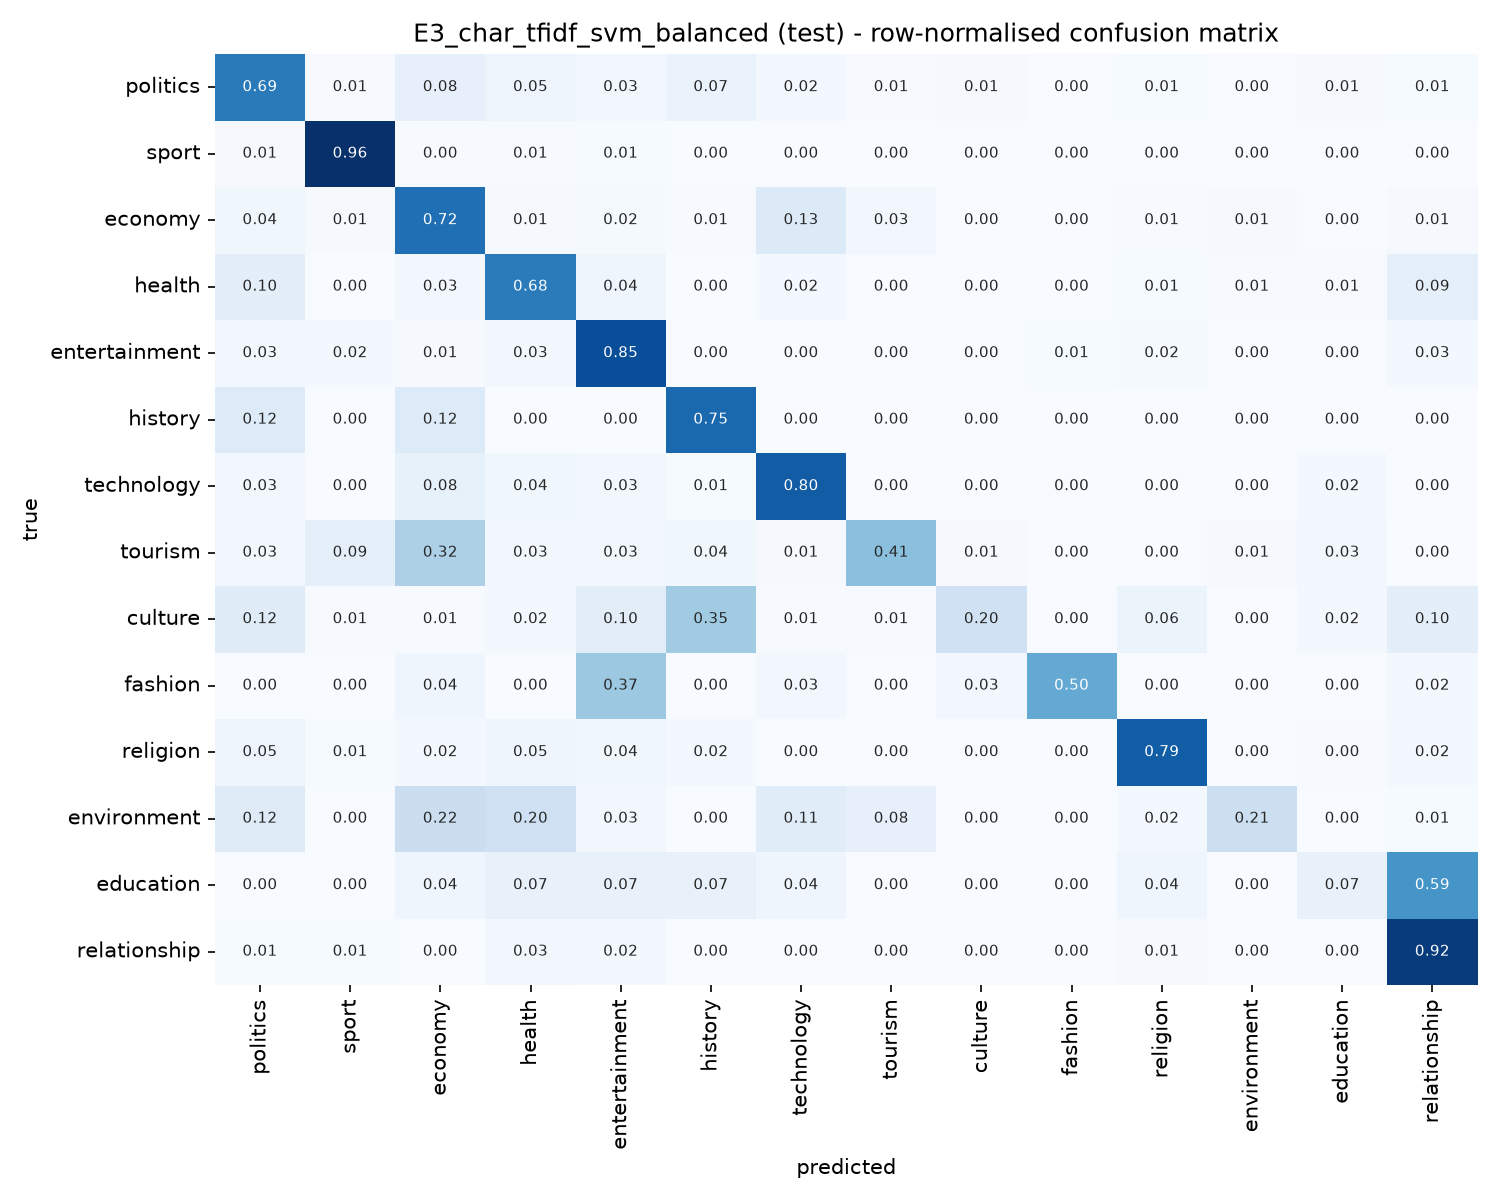

In [19]:
best = full["macro_f1"].idxmax()
print("best model:", best)
report = json.loads((RESULTS_DIR / best / "test_report.json").read_text())
per_class = pd.DataFrame({l: report[l] for l in LABELS}).T[["precision", "recall", "f1-score", "support"]]
per_class.insert(0, "train docs", train["label"].value_counts())
display(per_class.round(3).sort_values("train docs", ascending=False))
Image(str(FIGURES_DIR / f"cm_{best}_test.png"), width=650)

## 13. Error analysis
### 13.1 F1 per class for every model

,train docs,E1_tfidf_logreg,E2_tfidf_logreg_balanced,E3_char_tfidf_svm_balanced,E4_bilstm_random,E5_bilstm_w2v,E6_afroxlmr_mini
politics,1590,0.61,0.63,0.67,0.58,0.61,0.61
economy,998,0.55,0.55,0.61,0.46,0.51,0.39
health,975,0.58,0.63,0.66,0.49,0.51,0.49
entertainment,895,0.80,0.82,0.85,0.77,0.80,0.79
sport,877,0.94,0.94,0.96,0.89,0.89,0.92
religion,401,0.62,0.71,0.82,0.61,0.60,0.66
relationship,375,0.80,0.82,0.82,0.67,0.71,0.78
history,199,0.12,0.11,0.12,0.03,0.09,0.11
technology,135,0.55,0.69,0.68,0.58,0.67,0.61
education,104,0.05,0.13,0.11,0.11,0.11,0.06


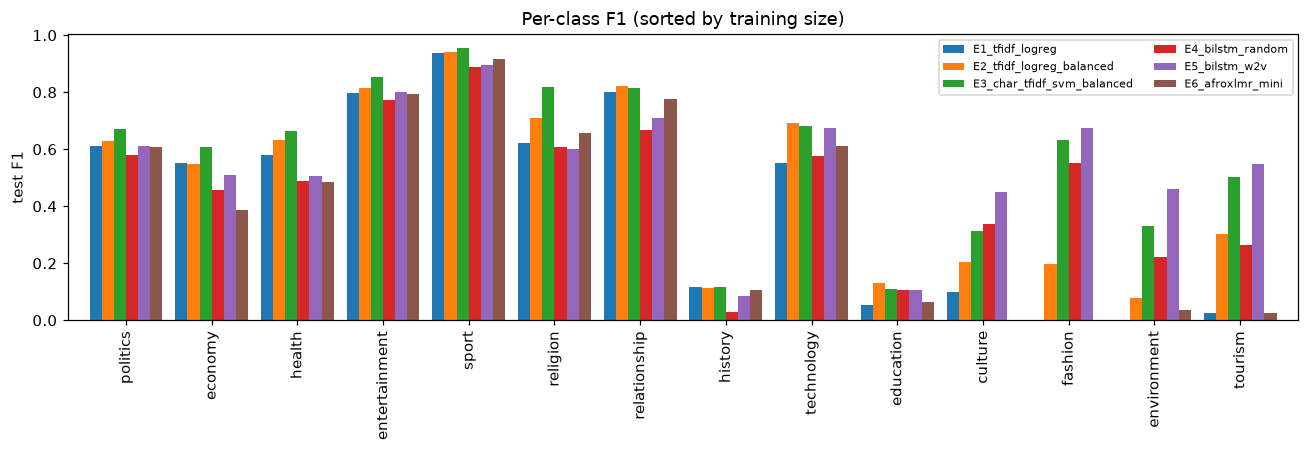

In [20]:
models = [m for m in full.index if m != "E0_majority"]
f1 = pd.DataFrame({m: {l: json.loads((RESULTS_DIR / m / "test_report.json").read_text())[l]["f1-score"]
                      for l in LABELS} for m in models})
f1.insert(0, "train docs", train["label"].value_counts())
f1 = f1.sort_values("train docs", ascending=False)
f1.round(3).to_csv(RESULTS_DIR / "per_class_f1.csv")
display(f1.round(2))

f1.drop(columns="train docs").plot.bar(figsize=(12, 4.2), width=0.85)
plt.ylabel("test F1"); plt.title("Per-class F1 (sorted by training size)")
plt.legend(fontsize=7, ncol=2); plt.tight_layout(); plt.savefig(FIGURES_DIR / "per_class_f1.png", dpi=150); plt.show()

- F1 follows the amount of training data: sport 0.96 vs education 0.11.
- The BiLSTM (E5) beats the SVM on the four smallest topics (culture, fashion, environment, tourism), so embeddings generalise better from few examples.
- E6 never predicts culture or fashion.

### 13.2 Most common mistakes

In [21]:
def predictions(model):
    p = pd.read_csv(RESULTS_DIR / model / "test_predictions.csv")
    p["correct"] = p["label"] == p["pred"]
    p["source"] = source(test["url"])
    p["n_words"] = p["text"].str.split().str.len()
    return p

pred = predictions(best)
pairs = Counter(zip(pred.loc[~pred.correct, "label"], pred.loc[~pred.correct, "pred"]))
pd.DataFrame(pairs.most_common(10), columns=["(true, predicted)", "count"])

,"(true, predicted)",count
0,"(culture, history)",48
1,"(education, relationship)",41
2,"(fashion, entertainment)",33
3,"(health, politics)",27
4,"(entertainment, health)",25
5,"(politics, economy)",25
6,"(health, relationship)",24
7,"(tourism, economy)",24
8,"(economy, technology)",23
9,"(entertainment, politics)",22


In [22]:
def show(true, predicted, n=4):
    rows = pred[(pred.label == true) & (pred.pred == predicted)]
    display(Markdown(f"**{true} → {predicted}** ({len(rows)} articles)"))
    display(rows["title"].str.strip().head(n).to_frame())

for t, p in [("culture", "history"), ("education", "relationship"), ("health", "politics"), ("fashion", "entertainment")]:
    show(t, p)

**culture → history** (48 articles)

,title
2156,Musenyeri Mbonyintege yanenze bimwe mu byavugiwe mu Kwibuka i Kabgayi
2158,Amateka: Ibyo wamenya ku muhango wo guterekera wakorwaga mu Rwanda rwo hambere
2170,AMATEKA-Bimwe mu byaranze Ingoma ya Kigeli II Nyamuheshera
2176,Inkomoko y’insigamugani umugabo mbwa aseka imbohe


**education → relationship** (41 articles)

,title
2083,Abageni 2 bataye ubukwe bwabo bajya mu kizamini
2092,Ibisobanuro by’izina Briella n’imico ikunze kuranga abaryitwa
2093,Ibisobanuro by’inzozi zirimo umusarane
2097,Ibisobanuro by’inzozi zitandukanye zirimo inzuki


**health → politics** (27 articles)

,title
1782,ICASA 2019: Abagore b’abakuru b’ibihugu by’Afurika mu cyerekezo kugira Afurika izira SIDA
1786,Huye: Umugore afunzwe akekwaho kwica umwana we w’ukwezi kumwe amuroze
1792,Nagambanye na basaza banjye ngo twice umugabo wanjye kuko yancaga inyuma
1793,RIB yafashe abakekwaho kwica umugabo bakamusiga mu ivatiri barimo umugore we n’abasaza be


**fashion → entertainment** (33 articles)

,title
2495,Ivumburamatsiko kuri Fred Lyon wambika benshi mu byamamare nyarwanda
2499,Kim Kardashian yahinduye izina ry’imideli ye nyuma yo kotswa igitutu n’Abayapani
2501,Imyambarire igezweho mu banyamujyi b’abanyabirori (Amafoto)
2503,Kardashian agiye guhindura izina ry’imyambaro y’imbere yatumye yamaganwa n’Abayapani


Reading the titles, many mistakes are really label disagreements:
- **culture → history**: articles about the monarchy and traditions, some titled *Amateka* ("history").
- **education → relationship**: test websites file dream meanings and name meanings under "education".
- **health → politics**: one test website labels crime and accident reports as "health".
- **fashion → entertainment**: celebrity stories fit both.

### 13.3 Source website, article length and unseen words

In [23]:
train_sources = set(source(train["url"]))
by_source = pd.DataFrame({m: predictions(m).groupby("source")["correct"].mean() for m in models}).round(3)
by_source.insert(0, "seen in train", [s in train_sources for s in by_source.index])
by_source.insert(1, "articles", pred.groupby("source").size())
display(Markdown("**Accuracy by website**")); display(by_source)

bins = pd.cut(pred["n_words"], [0, 150, 300, 500, 1000, 100_000], labels=["<150", "150-300", "300-500", "500-1000", ">1000"])
display(Markdown(f"**Accuracy by length ({best})**"))
display(pred.groupby(bins, observed=True)["correct"].agg(["mean", "size"]).round(3))

oov = pred["text"].map(lambda t: np.mean([w not in vocab for w in t.split()]))
print(f"share of unseen words: correct {oov[pred.correct].mean():.3f}, wrong {oov[~pred.correct].mean():.3f}")

**Accuracy by website**

,seen in train,articles,E1_tfidf_logreg,E2_tfidf_logreg_balanced,E3_char_tfidf_svm_balanced,E4_bilstm_random,E5_bilstm_w2v,E6_afroxlmr_mini
source,,,,,,,,
igihe.com,False,1201,0.558,0.602,0.679,0.590,0.669,0.521
kigalipost.com,False,671,0.618,0.614,0.599,0.556,0.590,0.511
muhabura.rw,True,1584,0.822,0.852,0.891,0.689,0.713,0.849


**Accuracy by length (E3_char_tfidf_svm_balanced)**

,mean,size
n_words,,
<150,0.788,312
150-300,0.791,1401
300-500,0.773,1128
500-1000,0.679,523
>1000,0.533,92


share of unseen words: correct 0.045, wrong 0.051


- Every model is worse on websites it never saw: E3 goes from 0.89 to 0.60-0.68, and E6 drops the most (0.85 → 0.51).
- Very long articles are harder (0.53 above 1,000 words); they often mix topics.
- Unseen words barely matter (5.1% in wrong vs 4.5% in correct predictions).

### 13.4 Examples it gets right

In [24]:
right = pred[pred.correct & pred.label.isin(["tourism", "fashion", "environment", "technology", "religion"])]
right.groupby("label").head(2)[["label", "pred", "title"]]

,label,pred,title
577,religion,religion,Bwa mbere ku irayidi Mufti w’u Rwanda yavuze ku butumwa bwa Vaticani
578,religion,religion,Umuyobozi wa Dove Hotel yaguwe gitumo yakira ruswa y’akayabo k’ibihumbi 500frw
2068,technology,technology,\nAbantu 9 bapfiriye mu mpanuka kubera ‘Facebook live’\n
2377,technology,technology,Sobanukirwa uko internet ya 5G izahindura ubuzima bwa muntu
2438,tourism,tourism,Uburyo bushya ushobora gusura ingagi zo mu birunga wibereye mu rugo
2439,tourism,tourism,"Afurika y’Epfo: COVID-19 yatumye intare zibona ubwisanzure , ziri kugaragara ziryamye mu mihanda (amafoto)"
2496,fashion,fashion,Miss Akiwacu Colombe yitabiriye Paris Fashion Week (Amafoto)
2497,fashion,fashion,Umusore uzahagararira u Rwanda muri ‘Mister Africa 2019’ yamenyekanye
2556,environment,environment,Hari kwigwa uko hakorwa amacupa ashobora kubora mu mwaka umwe
2561,environment,environment,"‘Earth Day’, umunsi wahariwe kwiyemeza guhangana n’ibibazo byugarije ibidukikije ku Isi"


## 14. Using the models (same code as the web app)
`src/inference.py` loads the saved models and applies the same preprocessing as training. `app.py` (Gradio) calls it and shows the topic, the top 5 scores and every model's prediction.

In [25]:
from src.inference import load_models

app_models = load_models()
samples = {
    "sport": "Rayon Sports yatsinze APR FC ibitego bibiri kuri kimwe mu mukino wa shampiyona wabereye kuri Stade Amahoro.",
    "health": "Minisiteri y’Ubuzima yatangaje ko abantu barenga ibihumbi icumi bamaze gukingirwa indwara ya COVID-19.",
    "religion": "Abakirisitu ba Kiliziya Gatolika bizihije umunsi mukuru wa Pasika muri Paruwasi ya Kabgayi.",
    "short / unclear": "Umuhanzi yashyize hanze indirimbo nshya.",
}
rows = []
for expected, s in samples.items():
    for name, m in app_models.items():
        scores = m(s)
        top = max(scores, key=scores.get)
        rows.append({"input (expected)": expected, "model": name, "prediction": top, "score": round(float(scores[top]), 3)})
pd.DataFrame(rows)

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:  20%|█▉        | 40/201 [00:00<00:00, 395.24it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 1475.30it/s]

,input (expected),model,prediction,score
0,sport,Char TF-IDF + LinearSVC (E3),sport,0.636
1,sport,AfroXLMR-mini fine-tuned (E6),sport,0.798
2,sport,BiLSTM + Word2Vec (E5),sport,1.000
3,health,Char TF-IDF + LinearSVC (E3),health,0.214
4,health,AfroXLMR-mini fine-tuned (E6),health,0.266
5,health,BiLSTM + Word2Vec (E5),health,0.999
6,religion,Char TF-IDF + LinearSVC (E3),religion,0.327
7,religion,AfroXLMR-mini fine-tuned (E6),religion,0.275
8,religion,BiLSTM + Word2Vec (E5),religion,0.998
9,short / unclear,Char TF-IDF + LinearSVC (E3),entertainment,0.606


- All three models agree on clear inputs.
- The short, vague sentence ("an artist released a new song") gets different answers: entertainment from the SVM and BiLSTM, religion from E6.
- The SVM's scores are only relative, and the BiLSTM is overconfident (≈1.0 even when unsure).

## 15. Limitations and conclusion

**Limitations**
- Only 6.7k training articles after deduplication; six topics have under 200.
- Half the test set is from unseen websites with their own category definitions.
- Transformers read only 128 tokens with frozen embeddings (CPU limits).
- One run per setting, no hyperparameter search.

**Next steps:** longer inputs on a GPU, KinyaBERT, more news sources, multi-label topics.

## Conclusion

- Checking the data mattered most: half the training set was duplicates, and the published ~88% only shows up when duplicates leak into evaluation.
- The best model is a character n-gram SVM (76.1% accuracy, 0.577 macro-F1). It fits Kinyarwanda's word forms and is fast.
- Neural models helped on rare topics but didn't win overall with this little data and compute.
- Most remaining errors come from unseen websites and inconsistent category definitions, not from the language itself.

## References

- Adelani, D. I., et al. (2023). MasakhaNEWS: News topic classification for African languages. *IJCNLP-AACL 2023*.
- Alabi, J. O., Adelani, D. I., Mosbach, M., & Klakow, D. (2022). Adapting pre-trained language models to African languages via multilingual adaptive fine-tuning. *COLING 2022*.
- Bahdanau, D., Cho, K., & Bengio, Y. (2015). Neural machine translation by jointly learning to align and translate. *ICLR 2015*.
- Conneau, A., et al. (2020). Unsupervised cross-lingual representation learning at scale. *ACL 2020*.
- Hochreiter, S., & Schmidhuber, J. (1997). Long short-term memory. *Neural Computation, 9*(8).
- Mikolov, T., et al. (2013). Distributed representations of words and phrases and their compositionality. *NeurIPS 2013*.
- Niyongabo, R. A., Qu, H., Kreutzer, J., & Huang, L. (2020). KINNEWS and KIRNEWS: Benchmarking cross-lingual text classification for Kinyarwanda and Kirundi. *COLING 2020*.
- Nzeyimana, A., & Niyongabo Rubungo, A. (2022). KinyaBERT: A morphology-aware Kinyarwanda language model. *ACL 2022*.
- Wang, W., et al. (2021). MiniLMv2: Multi-head self-attention relation distillation for compressing pretrained Transformers. *Findings of ACL 2021*.
- Wolf, T., et al. (2020). Transformers: State-of-the-art natural language processing. *EMNLP 2020: System Demonstrations*.